# Sesión 04
## Análisis Exploratorio de Datos
Dificultad 😀😀😀😀 (Media)  
Uso de código: 🐍🐍 (moderado)
- Clase octubre de 2026

### 🎯 ¿Por qué es importante el EDA?

El Análisis Exploratorio de Datos (EDA, Exploratory Data Analysis) es una etapa fundamental en los proyectos de Machine Learning, ya que permite comprender, analizar y evaluar la calidad de los datos antes de entrenar un modelo.

### 1. 🧹 Asegurar la calidad de los datos

"Basura que entra, basura que sale" (Garbage In, Garbage Out).

La precisión y efectividad de un modelo de Machine Learning dependen directamente de la calidad e integridad del conjunto de entrenamiento.

El EDA permite auditar el dataset para identificar y corregir imperfecciones antes de avanzar con el modelado.

Detección y tratamiento de problemas de calidad
Valores nulos o faltantes: Permite cuantificar cuántos datos faltan mediante inspecciones como df.info() o df.isnull().sum(), para evaluar si deben eliminarse o imputarse. Por ejemplo, reemplazándolos por la mediana o la moda.
Registros duplicados: Ayuda a detectar y eliminar filas idénticas con df.drop_duplicates(), evitando posibles sesgos en el análisis y el entrenamiento del modelo.
Valores atípicos (Outliers): Facilita la detección de anomalías o valores extremos mediante métodos estadísticos como el Rango Intercuartílico (IQR) o el Z-Score.
Tipos de datos inconsistentes: Verifica que cada columna tenga el tipo de dato correcto (int, float, object o datetime), permitiendo realizar conversiones, cálculos y agrupaciones de forma adecuada.

### 2. 📊 Comprender la estructura y escala de las variables

El EDA permite clasificar las variables según su naturaleza:

Cualitativas:
Nominales.
Ordinales.
Cuantitativas:
Discretas.
Continuas.

Esta clasificación orienta el preprocesamiento necesario para preparar los datos, por ejemplo:

Codificación de variables categóricas: Conversión de categorías a representaciones numéricas mediante técnicas como One-Hot Encoding y Ordinal Encoding.
Escalado de características numéricas (Feature Scaling): Transformación de las escalas de las variables numéricas para facilitar el entrenamiento de determinados modelos de Machine Learning.

### 3. 🔎 Descubrir patrones, distribuciones y relaciones

A través del cálculo de estadísticas descriptivas y la creación de gráficos exploratorios, el EDA permite comprender cómo se comportan las variables y qué relaciones existen entre ellas.

Estadísticas descriptivas

Algunas de las medidas más utilizadas son:

Media: Representa el promedio de los valores.
Mediana: Identifica el valor central de una distribución ordenada.
Desviación estándar: Mide la dispersión de los datos respecto a la media.
Cuartiles: Dividen los datos ordenados en cuatro partes.
Visualización de datos

Mediante librerías de Python como Matplotlib y Seaborn, es posible generar gráficos como:

Histogramas: Permiten analizar la distribución de una variable numérica.
Diagramas de caja (Box Plots): Facilitan la identificación de valores atípicos y la dispersión de los datos.
Gráficos de dispersión (Scatter Plots): Ayudan a identificar relaciones entre dos variables numéricas.
Mapas de calor (Heatmaps): Permiten visualizar matrices de correlación y detectar posibles relaciones entre variables.

Estas herramientas ayudan a identificar tendencias, anomalías, patrones y posibles correlaciones que podrían influir en el rendimiento del modelo.

### 4. 💼 Validar hipótesis de negocio

El EDA permite comprobar si los datos recopilados responden a la problemática real del negocio planteada al inicio del proyecto.

Mediante el análisis de los datos, es posible:

Verificar si la información disponible es relevante para el problema.
Identificar tendencias relacionadas con los objetivos del negocio.
Evaluar si los datos permiten responder las preguntas planteadas.
Detectar limitaciones o sesgos que puedan afectar las conclusiones.

### ✅ Conclusión

El EDA es una etapa esencial antes de entrenar un modelo de Machine Learning, porque permite asegurar la calidad de los datos, comprender las variables, descubrir patrones y validar las hipótesis del negocio.

Un análisis exploratorio adecuado facilita la toma de decisiones durante el preprocesamiento y contribuye a desarrollar modelos más confiables y adecuados para el problema que se busca resolver.

- **Tratamiento de Datos Perdidos:** ¿Borras la fila o imputas el valor? (Recuerda: la Mediana es tu mejor amiga para imputar si hay outliers).
- **Gestión de Outliers:** Decidir si los valores extremos son errores de medición o casos reales pero raros que el modelo debe conocer.
- **Hito Principal:** Un conjunto de datos sin faltantes (NaN) y con ruido controlado.


In [1]:
# Librerías necesarias..

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploración de datos

In [3]:
# Exploración de set de datos "trabajosIA"..

In [4]:
# llamar al archivo CSV que esta en data "trabajosIA.csv" y guardarlo en un dataframe llamado "df_trabajosIA"
df1 = pd.read_csv("data/trabajosIA.csv", encoding="utf-8")

In [5]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12425 entries, 0 to 12424
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   titulo_puesto                 12423 non-null  object 
 1   pais                          12423 non-null  object 
 2   nivel_experiencia             12423 non-null  object 
 3   nivel_educacion               12423 non-null  object 
 4   año_                          12423 non-null  float64
 5   salario                       12423 non-null  float64
 6   puntuacion_riesgo_ia          12423 non-null  float64
 7   habilidad_principal           12423 non-null  object 
 8   puntuacion_demanda_habilidad  12423 non-null  float64
 9   vacantes_laborales            12423 non-null  float64
 10  clase_supervivencia_puesto    12423 non-null  float64
 11  categoria_salario             12423 non-null  object 
 12  categoria_riesgo_ia           12423 non-null  object 
dtypes

In [6]:
# 2. Renombrar la quinta columna (índice 4) a 'año'
df1.rename(columns={df1.columns[4]: "año"}, inplace=True)

# 3. Verificar los nombres de columnas
print(df1.columns.tolist())

['titulo_puesto', 'pais', 'nivel_experiencia', 'nivel_educacion', 'año', 'salario', 'puntuacion_riesgo_ia', 'habilidad_principal', 'puntuacion_demanda_habilidad', 'vacantes_laborales', 'clase_supervivencia_puesto', 'categoria_salario', 'categoria_riesgo_ia']


In [7]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12425 entries, 0 to 12424
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   titulo_puesto                 12423 non-null  object 
 1   pais                          12423 non-null  object 
 2   nivel_experiencia             12423 non-null  object 
 3   nivel_educacion               12423 non-null  object 
 4   año                           12423 non-null  float64
 5   salario                       12423 non-null  float64
 6   puntuacion_riesgo_ia          12423 non-null  float64
 7   habilidad_principal           12423 non-null  object 
 8   puntuacion_demanda_habilidad  12423 non-null  float64
 9   vacantes_laborales            12423 non-null  float64
 10  clase_supervivencia_puesto    12423 non-null  float64
 11  categoria_salario             12423 non-null  object 
 12  categoria_riesgo_ia           12423 non-null  object 
dtypes

In [8]:
# Explora los primeros registros del dataser trabajosIA


In [9]:
df1 .head(10)

,titulo_puesto,pais,nivel_experiencia,nivel_educacion,año,salario,puntuacion_riesgo_ia,habilidad_principal,puntuacion_demanda_habilidad,vacantes_laborales,clase_supervivencia_puesto,categoria_salario,categoria_riesgo_ia
0,Científico de Datos,EE. UU.,Senior,Maestria,2022.0,61931.03,0.32,Python,88.0,39158.0,2.0,Alto,Riesgo Medio
1,Ingeniero de Software,India,Senior,Licenciatura,2032.0,21330.84,0.52,Java,80.0,7265.0,1.0,Alto,Riesgo Medio
2,Científico de Datos,Canada,Intermedio,Licenciatura,2015.0,24211.17,0.25,Python,70.0,22962.0,1.0,Alto,Riesgo Bajo
3,Científico de Datos,India,Inicial,Doctorado,2034.0,11794.86,0.44,Python,95.0,17023.0,1.0,Medio,Riesgo Medio
4,Analista de Datos,Canada,Inicial,Doctorado,2035.0,17999.26,0.75,SQL,61.0,3433.0,0.0,Medio,Riesgo Alto
5,Ingeniero DevOps,Reino Unido,Inicial,Maestria,2033.0,29676.40,0.38,Docker,80.0,18568.0,1.0,Alto,Riesgo Medio
6,Analista de Ciberseguridad,EE. UU.,Inicial,Doctorado,2028.0,27813.44,0.28,Seguridad,81.0,7396.0,1.0,Alto,Riesgo Bajo
7,Ingeniero Cloud,Alemania,Inicial,Licenciatura,2025.0,24684.38,0.35,AWS,86.0,26658.0,1.0,Alto,Riesgo Medio
8,Científico de Datos,EE. UU.,Intermedio,Licenciatura,2026.0,45617.71,0.36,Python,87.0,3747.0,2.0,Alto,Riesgo Medio
9,Ingeniero Cloud,Canada,Intermedio,Licenciatura,2029.0,39526.54,0.39,AWS,62.0,4556.0,1.0,Alto,Riesgo Medio


#### Set de datos TrabajoIA

Este conjunto de datos explora la relación en constante evolución entre la inteligencia artificial, los mercados laborales, las habilidades y los salarios en todo el mundo desde 2015 hasta 2035.

Con el rápido auge de las tecnologías de IA, preguntas como "¿La IA reemplazará mi trabajo?" y "¿Qué habilidades sobresalen en el futuro?" se han vuelto más relevantes que nunca. Este conjunto de datos está diseñado para responder a estas preguntas mediante análisis basados ​​en datos y funciones listas para la visualización.

In [10]:
# tipos de datos de cada columna del dataset trabajosIA..

In [11]:
# Tipos de datos
df1.dtypes

titulo_puesto                    object
pais                             object
nivel_experiencia                object
nivel_educacion                  object
año                             float64
salario                         float64
puntuacion_riesgo_ia            float64
habilidad_principal              object
puntuacion_demanda_habilidad    float64
vacantes_laborales              float64
clase_supervivencia_puesto      float64
categoria_salario                object
categoria_riesgo_ia              object
dtype: object

In [12]:
# Contar valores perdidos en cada columna del dataset trabajosIA...

In [13]:
# Valores perdidos
df1.isnull().sum()

titulo_puesto                   2
pais                            2
nivel_experiencia               2
nivel_educacion                 2
año                             2
salario                         2
puntuacion_riesgo_ia            2
habilidad_principal             2
puntuacion_demanda_habilidad    2
vacantes_laborales              2
clase_supervivencia_puesto      2
categoria_salario               2
categoria_riesgo_ia             2
dtype: int64

In [14]:
# Muestra en grafica los valores perdidos df1..

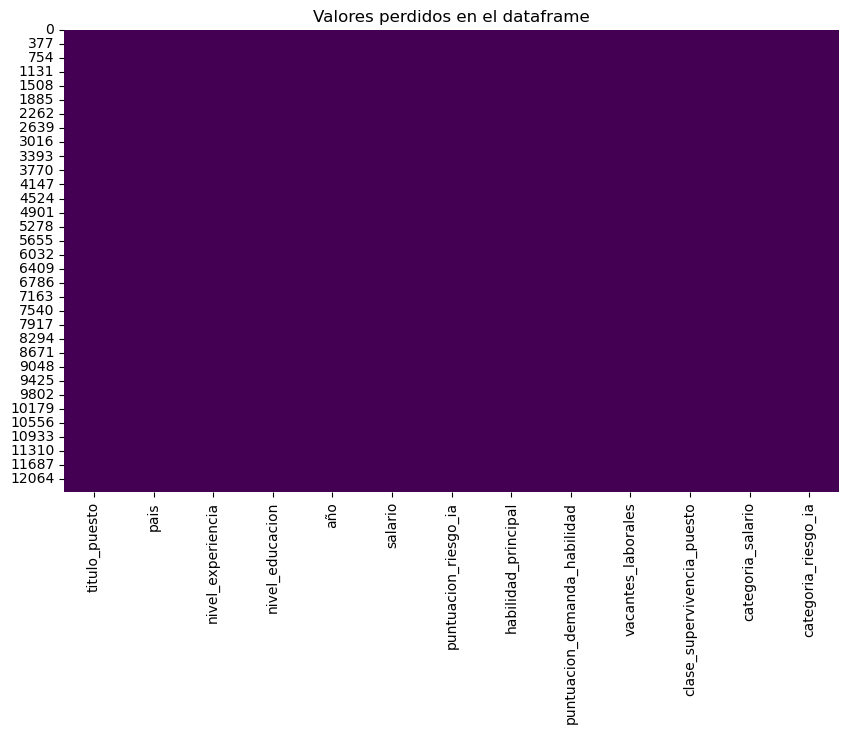

In [15]:
# Valores perdidos de manera grafica
plt.figure(figsize=(10, 6))
sns.heatmap(df1.isnull(), cbar=False, cmap='viridis')
plt.title("Valores perdidos en el dataframe")
plt.show()


In [16]:
# Conteo de tipos de datos en df1..

In [17]:
# Conteo de tipos de datos
df1.dtypes.value_counts()

object     7
float64    6
Name: count, dtype: int64

### Tratamientos de variables

| Tipo de dato | Uso típico | Ejemplo de columnas en `df1` | Cómo convertir |
|---|---|---|---|
| `int` | Números enteros | `año`, `vacantes_laborales`, `clase_supervivencia_puesto` | `df1["col"] = df1["col"].astype(int)` |
| `float` | Números decimales | `salario`, `puntuacion_riesgo_ia`, `puntuacion_demanda_habilidad` | `df1["col"] = df1["col"].astype(float)` |
| `object` (string) | Texto | `titulo_puesto`, `pais`, `habilidad_principal` | `df1["col"] = df1["col"].astype(str)` |
| `category` | Variables categóricas | `nivel_experiencia`, `nivel_educacion`, `categoria_salario`, `categoria_riesgo_ia` | `df1["col"] = df1["col"].astype("category")` |
| `bool` | Verdadero / Falso | No hay columnas booleanas evidentes | `df1["col"] = df1["col"].astype(bool)` |
| `datetime64[ns]` | Fechas y tiempo | No hay columnas de fecha; `a�o_` representa el año | `df1["col"] = pd.to_datetime(df1["col"])` |

> **Nota:** `df1` contiene valores faltantes y las columnas numéricas aparecen como `float`. Resuelve los `NaN` antes de convertir una columna a `int`.

In [18]:
# Resumen de tipos datos..

In [19]:
resumen_datos = df1.dtypes.reset_index()
resumen_datos.columns = ["variable", "tipo_de_dato"]
resumen_datos["tipo_de_dato"] = resumen_datos["tipo_de_dato"].astype(str) # Convertir a string para evitar problemas de comparación
resumen_datos


,variable,tipo_de_dato
0,titulo_puesto,object
1,pais,object
2,nivel_experiencia,object
3,nivel_educacion,object
4,año,float64
5,salario,float64
6,puntuacion_riesgo_ia,float64
7,habilidad_principal,object
8,puntuacion_demanda_habilidad,float64
9,vacantes_laborales,float64


In [20]:
resumen_datos = pd.DataFrame(
    {"variable": df1.columns, "tipo_de_dato": df1.dtypes.astype(str).values}
)
resumen_datos

,variable,tipo_de_dato
0,titulo_puesto,object
1,pais,object
2,nivel_experiencia,object
3,nivel_educacion,object
4,año,float64
5,salario,float64
6,puntuacion_riesgo_ia,float64
7,habilidad_principal,object
8,puntuacion_demanda_habilidad,float64
9,vacantes_laborales,float64


In [21]:
# Muestra valores únicos de la variable "titulo_puesto" del dataset trabajosIA..

In [22]:
# valores unico en titulo_puesto
df1["titulo_puesto"].unique()

array(['Científico de Datos', 'Ingeniero de Software',
       'Analista de Datos', 'Ingeniero DevOps',
       'Analista de Ciberseguridad', 'Ingeniero Cloud',
       'Analista de Negocios', 'Investigador de IA', 'Ingeniero de ML',
       'Gerente de Producto', nan, 'Cient√≠fico de Datos'], dtype=object)

In [23]:
# muestra valores unico en la variables "año" del dataset trabajosIA..

In [24]:
# valores unicos en año
df1["año"].unique()

array([2022., 2032., 2015., 2034., 2035., 2033., 2028., 2025., 2026.,
       2029., 2027., 2020., 2023., 2016., 2021., 2031., 2030., 2017.,
       2019., 2024., 2018.,   nan])

In [25]:
# Convierte la columna "año" a tipo de dato mas optimo.


In [26]:
# Valores únicos en el dataset trabajosIA
valores_unicos = df1.nunique()
valores_unicos


titulo_puesto                      11
pais                                7
nivel_experiencia                   4
nivel_educacion                     4
año                                21
salario                         12326
puntuacion_riesgo_ia               83
habilidad_principal                 9
puntuacion_demanda_habilidad       40
vacantes_laborales              10911
clase_supervivencia_puesto          3
categoria_salario                   3
categoria_riesgo_ia                 3
dtype: int64

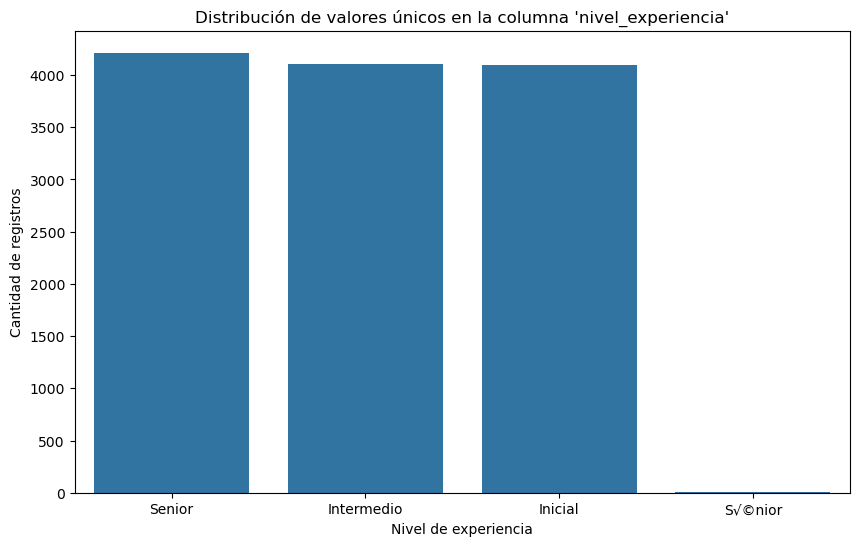

In [27]:
# Grafica de valores unico en df1..
plt.figure(figsize=(10, 6))
sns.countplot(data=df1, x="nivel_experiencia", order=df1["nivel_experiencia"].value_counts().index)
plt.title("Distribución de valores únicos en la columna 'nivel_experiencia'")
plt.xlabel("Nivel de experiencia")
plt.ylabel("Cantidad de registros")
plt.show()

In [28]:
# Vaores unicos de la variable "nivel_experiencia" del dataset df1..
print(df1["nivel_experiencia"].value_counts())


nivel_experiencia
Senior        4213
Intermedio    4105
Inicial       4100
S√©nior          5
Name: count, dtype: int64


In [29]:
# ¿Cómo unificar los valores y por que es importante unificar los valores de una columna en un dataset?
#
# Unificar los valores de una columna en un dataset es importante porque:
# 1. Mejora la calidad de los datos.
# 2. Facilita el análisis y la interpretación de los resultados.
# 3. Permite una mejor toma de decisiones basada en datos confiables.

# Reemplazar cualquier texto que coincida con patrones irregulares de Senior
df1["nivel_experiencia"] = df1["nivel_experiencia"].str.replace(
    r"^S.*nior$", "Senior", regex=True
)

# Verificar la unificación de los conteos
print(df1["nivel_experiencia"].value_counts())


nivel_experiencia
Senior        4218
Intermedio    4105
Inicial       4100
Name: count, dtype: int64


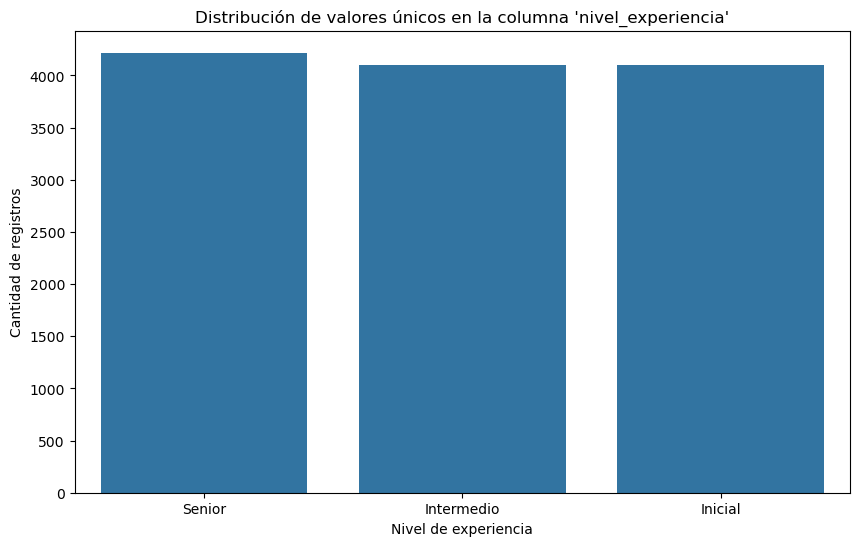

In [30]:
# Grafica de valores unico en df1..
plt.figure(figsize=(10, 6))
sns.countplot(data=df1, x="nivel_experiencia", order=df1["nivel_experiencia"].value_counts().index)
plt.title("Distribución de valores únicos en la columna 'nivel_experiencia'")
plt.xlabel("Nivel de experiencia")
plt.ylabel("Cantidad de registros")
plt.show()

In [31]:
# Explora que otras variables es necesario unificar en el dataset trabajosIA y por que es importante unificar los valores.
# 20 minutos.
# ...

## Valores perdidos

Buscar valores perdidos antes de entrenar un modelo de *machine learning* es importante porque pueden:

- Reducir la cantidad de datos útiles o impedir que algunos algoritmos funcionen.
- Sesgar los resultados si los valores faltan de forma sistemática.
- Alterar estadísticas y relaciones entre variables, afectando el rendimiento del modelo.
- Provocar errores al convertir tipos de datos o realizar cálculos.

Al detectarlos, se puede decidir cómo tratarlos: eliminar filas o columnas, imputar valores —por ejemplo, con la mediana en variables numéricas con outliers— o usar métodos específicos. La decisión debe considerar el contexto y evitar introducir sesgos adicionales.

Para identificar las filas con datos perdidos podemos usar `df[df.isna().any(axis=1)]`. El método *isna()* sirve para indicar qué valores son perdidos y el método *any* sirve para indicar qué filas tienen al menos un valor perdido.

In [33]:
# Mostrar filas con valores perdidos en el dataset trabajosIA..

In [34]:
# Filas con valores perdidos
valores_perdidos = df1[df1.isnull().any(axis=1)]
valores_perdidos

,titulo_puesto,pais,nivel_experiencia,nivel_educacion,año,salario,puntuacion_riesgo_ia,habilidad_principal,puntuacion_demanda_habilidad,vacantes_laborales,clase_supervivencia_puesto,categoria_salario,categoria_riesgo_ia
12390,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12391,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


- isna() → detecta nulos
- any(axis=1) → revisa por fila
- df1[...] → filtra de acuerdo a la condición de tus datos

 Resultado: filas con datos incompletos

#### RECUERDA EL TRATAMIENTO DE VALORES PERDIDOS
- Borrar filas o columnas con datos perdidos.
- Agregar una variable que distinga los datos perdidos.
- Imputación simple: Reemplazar los datos perdidos con un valor calculado a partir de la misma variable.
- Imputación multivariada: Reemplazar los datos perdidos con un valor calculado a partir de otras variables.  

**Imputación univariada**  
La práctica más común es reemplazar los valores con la media, mediana o moda. Una opción es utilizar la biblioteca de pandas. La imputación con la media para una columna 'A' es:  
`df['A'] = df['A'].fillna(df['A'].mean())`  
La imputación con la mediana es  
`df['A'] = df['A'].fillna(df['A'].median())` 
La imputación con la moda es:  
`df['A'] = df['A'].fillna(df['A'].mode().iloc[0])` 

Utiliza la media para reemplazar valores perdidos

In [35]:
# Imputación simple en df1 dataset trabajosIA..
# - Numéricas: media
# - Categóricas: moda

In [36]:
# Columnas numéricas: Imputar con la media
cols_numericas = df1.select_dtypes(include=["number"]).columns
for col in cols_numericas:
    df1[col] = df1[col].fillna(df1[col].mean()) # Imputar con la media

# Columnas categóricas/texto: Imputar con la moda
cols_categoricas = df1.select_dtypes(exclude=["number"]).columns
for col in cols_categoricas:
    if df1[col].isna().any():
        df1[col] = df1[col].fillna(df1[col].mode().iloc[0]) # Imputar con la moda

# Verificar que no queden valores perdidos
df1.isna().sum()

titulo_puesto                   0
pais                            0
nivel_experiencia               0
nivel_educacion                 0
año                             0
salario                         0
puntuacion_riesgo_ia            0
habilidad_principal             0
puntuacion_demanda_habilidad    0
vacantes_laborales              0
clase_supervivencia_puesto      0
categoria_salario               0
categoria_riesgo_ia             0
dtype: int64

In [37]:
# Revisa numero de filas y columnas en df1 después de la imputación..


In [38]:
# filas y columnas.
df1.shape

(12425, 13)

## Valores duplicados

Buscar y eliminar valores duplicados en un DataFrame de pandas es una etapa crítica en la limpieza de datos (data cleaning), esencial para asegurar la integridad, precisión y confiabilidad de cualquier análisis.

### La importancia de este proceso radica en los siguientes puntos:
-  Evitar el sesgo en el análisis estadístico: Los datos duplicados inflan artificialmente las cifras, lo que lleva a medias, medianas o sumas incorrectas. Por ejemplo, contar el mismo registro de venta dos veces puede alterar drásticamente los informes financieros.
- Mejorar la precisión de los modelos de ML: Los algoritmos pueden malinterpretar los datos duplicados como patrones fuertes, generando modelos de aprendizaje automático defectuosos o sesgados.
- Ahorro de recursos y optimización: Eliminar duplicados reduce el espacio de almacenamiento innecesario y disminuye la capacidad de procesamiento requerida para análisis posteriores.
- Garantizar la calidad del dato: Asegura que cada entidad (como un cliente, producto o transacción) esté representada una sola vez, lo que es vital para la gestión de relaciones con clientes (CRM) y sistemas de inventario.
- Evitar errores operativos: En marketing o logística, la duplicidad provoca acciones redundantes y costosas, como enviar múltiples catálogos al mismo cliente o gestionar stock inactivo.


- **df.duplicated()**: Identifica filas duplicadas y devuelve una serie booleana (True/False).
- **df.drop_duplicates()**: Elimina las filas duplicadas. El parámetro keep permite decidir si conservar la primera ('first'), la última ('last') o ninguna (False) de las apariciones.
- **subset**: Permite buscar duplicados basándose en columnas específicas, en lugar de toda la fila.


In [39]:
# Buscar filas duplicadas en df1 dataset trabajosIA..

In [40]:
#Filas duplicadas
df1[df1.duplicated()]

,titulo_puesto,pais,nivel_experiencia,nivel_educacion,año,salario,puntuacion_riesgo_ia,habilidad_principal,puntuacion_demanda_habilidad,vacantes_laborales,clase_supervivencia_puesto,categoria_salario,categoria_riesgo_ia
12343,Ingeniero Cloud,Australia,Intermedio,Licenciatura,2016.0,30482.82,0.26,AWS,86.0,11237.0,1.0,Alto,Riesgo Bajo
12344,Investigador de IA,EE. UU.,Inicial,Licenciatura,2034.0,54982.39,0.24,Deep Learning,96.0,19461.0,2.0,Alto,Riesgo Bajo
12345,Analista de Datos,EE. UU.,Intermedio,Maestria,2035.0,33562.18,0.75,SQL,79.0,13464.0,0.0,Alto,Riesgo Alto
12346,Ingeniero DevOps,Canada,Inicial,Maestria,2026.0,25906.60,0.31,Docker,84.0,14064.0,1.0,Alto,Riesgo Medio
12347,Ingeniero de ML,India,Intermedio,Licenciatura,2031.0,19059.88,0.31,Python,72.0,1932.0,1.0,Medio,Riesgo Medio
...,...,...,...,...,...,...,...,...,...,...,...,...,...
12419,Gerente de Producto,Australia,Intermedio,Maestria,2022.0,35278.39,0.37,Estrategia,91.0,47825.0,2.0,Alto,Riesgo Medio
12421,Ingeniero Cloud,Canada,Inicial,Licenciatura,2034.0,28517.46,0.44,AWS,99.0,42302.0,2.0,Alto,Riesgo Medio
12422,Gerente de Producto,Reino Unido,Inicial,Doctorado,2029.0,29561.30,0.44,Estrategia,66.0,14543.0,1.0,Alto,Riesgo Medio
12423,Gerente de Producto,EE. UU.,Inicial,Licenciatura,2016.0,31595.96,0.31,Estrategia,61.0,13817.0,1.0,Alto,Riesgo Medio


Buscar filas duplicadas en un conjunto de datos es importante porque pueden:

- **Distorsionar los análisis:** inflar conteos, sumas y promedios.
- **Introducir sesgos:** hacer que ciertos registros tengan más peso del que corresponde.
- **Afectar los modelos de *machine learning*:** provocar que el modelo aprenda patrones engañosos.
- **Desperdiciar recursos:** aumentar innecesariamente el tamaño y el procesamiento de los datos.

Antes de eliminarlas, conviene confirmar que sean duplicados reales: en algunos conjuntos de datos, dos registros iguales pueden representar eventos distintos y válidos.

In [41]:
# contar filas duplicadas
print (df1[df1.duplicated()].value_counts())

# Conteo total de filas duplicadas (retorna un solo número)
print (df1.duplicated().sum())

titulo_puesto               pais         nivel_experiencia  nivel_educacion  año          salario       puntuacion_riesgo_ia  habilidad_principal  puntuacion_demanda_habilidad  vacantes_laborales  clase_supervivencia_puesto  categoria_salario  categoria_riesgo_ia
Analista de Ciberseguridad  Alemania     Intermedio         Doctorado        2016.000000  2.204601e+04  0.160000              Seguridad            89.000000                     10527.000000        2.000000                    Alto               Riesgo Bajo            1
Ingeniero DevOps            Reino Unido  Inicial            Doctorado        2021.000000  2.389928e+04  0.260000              Docker               89.000000                     16114.000000        1.000000                    Alto               Riesgo Bajo            1
Ingeniero de ML             Reino Unido  Intermedio         Licenciatura     2027.000000  4.560967e+04  0.270000              Python               96.000000                     39105.000000        2

### Interpretación de las variables numericas 

In [42]:
# Gráfica de caja para interpretar las variables numéricas del dataset trabajosIA..

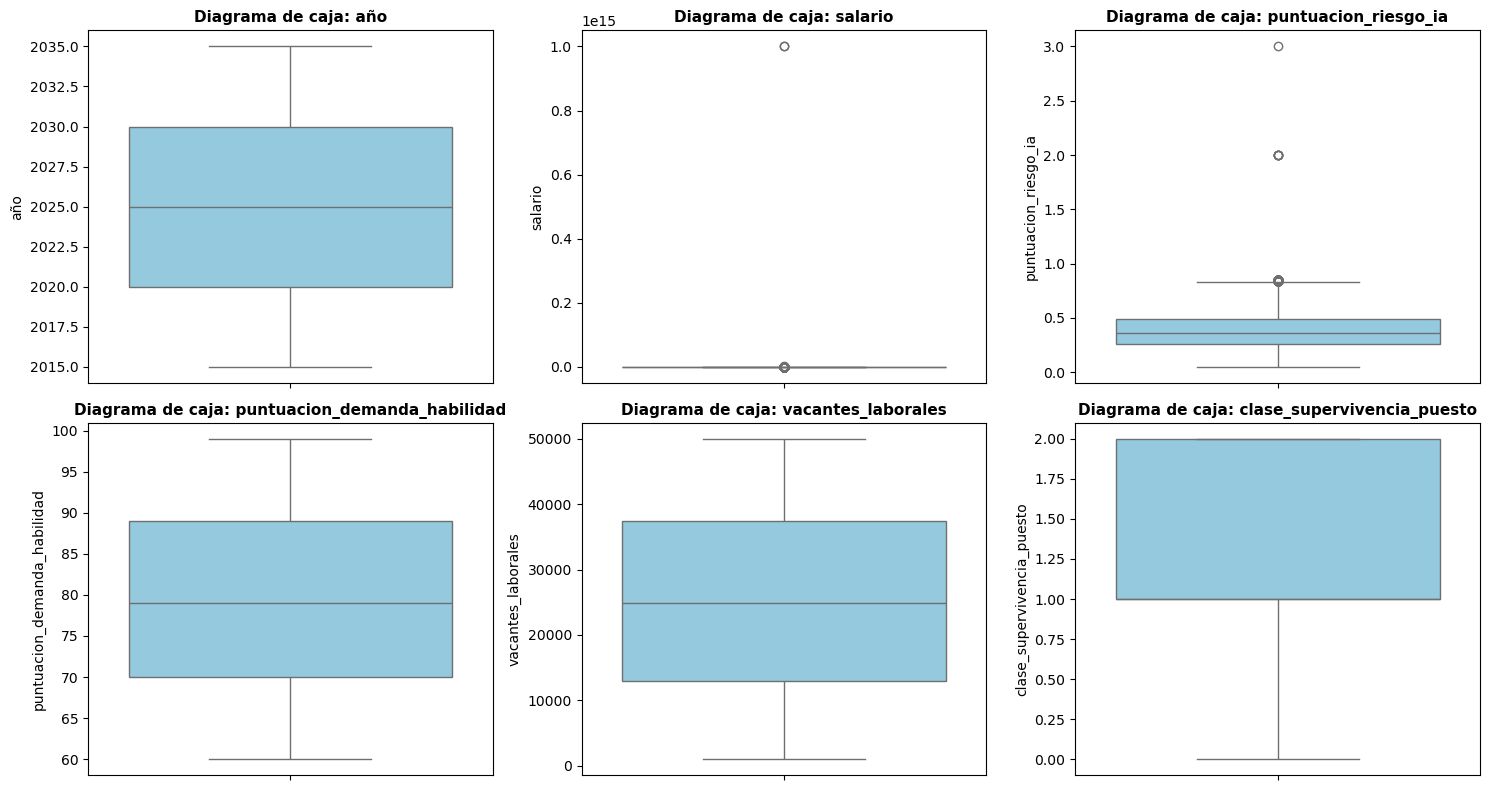

In [43]:

# 1. Seleccionar solo las columnas numéricas
numeric_cols = df1.select_dtypes(include=["number"]).columns
num_vars = len(numeric_cols)

# 2. Configurar la cuadrícula de subgráficos (3 columnas por fila)
cols = 3
rows = (num_vars + cols - 1) // cols  # Calcula las filas necesarias dinámicamente

fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))
axes = axes.flatten()  # Aplanar la matriz de ejes para iterar fácilmente

# 3. Graficar cada columna de manera independiente
for i, col in enumerate(numeric_cols):
    sns.boxplot(y=df1[col], ax=axes[i], color="skyblue")
    axes[i].set_title(f"Diagrama de caja: {col}", fontsize=11, fontweight="bold")
    axes[i].set_xlabel("")

# 4. Ocultar cuadros vacíos si la cuadrícula no es exacta
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# Valores atípicos
Los valores atípicos son valores muy alejados de la tendencia central de los datos. No es recomendable su eliminación automática, sino su revisión para evaluar si son parte o no de la muestra. Un método sencillo que podemos utilizar es el método del valor z.

# Valores Atípicos (Outliers)

## Características y Causas

- **Origen:**  
  Pueden ser errores genuinos (errores de entrada de datos) o variaciones legítimas que ofrecen información valiosa.

- **Impacto:**  
  Afectan notablemente las pruebas de hipótesis y los modelos predictivos.

- **Ejemplo:**  
  En un conjunto de salarios de $30,000–$60,000, un valor de $500,000 es un valor atípico.

---

## Métodos de Detección (Cómo encontrar valores atípicos)

### 📈 Gráficos
- Diagramas de caja (*boxplots*), donde los puntos fuera de los bigotes son considerados atípicos.

### 📐 Estadísticos
- **Puntuación Z (z-score):**  
  Valores mayores a 3 o menores a -3.

### 📊 Rango Intercuartílico (IQR)
- Valores por debajo de:  
  **Q1 − 1.5 × IQR**
- Valores por encima de:  
  **Q3 + 1.5 × IQR**

---

## 🛠️ Tratamiento de Valores Atípicos

- **Revisar:**  
  Determinar si es un error o un dato real.

- **Eliminar:**  
  Si es un error obvio.

- **Mantener:**  
  Si es información relevante y legítima.

- **Transformar:**  
  Aplicar logaritmos u otras transformaciones para reducir su impacto.

In [44]:
# Explora la estadística descriptiva de algunas variables numéricas del dataset trabajosIA..

In [45]:
df1.describe()

,año,salario,puntuacion_riesgo_ia,puntuacion_demanda_habilidad,vacantes_laborales,clase_supervivencia_puesto
count,12425.000000,1.242500e+04,12425.000000,12425.000000,12425.000000,12425.000000
mean,2025.059728,1.610722e+11,0.396858,79.458746,25219.309668,1.310151
std,6.060224,1.268672e+13,0.191838,11.479491,14161.265635,0.658541
min,2015.000000,3.875170e+03,0.050000,60.000000,1002.000000,0.000000
25%,2020.000000,2.136399e+04,0.260000,70.000000,12992.000000,1.000000
50%,2025.000000,3.158789e+04,0.360000,79.000000,24886.000000,1.000000
75%,2030.000000,4.533056e+04,0.490000,89.000000,37447.000000,2.000000
max,2035.000000,1.000000e+15,3.000000,99.000000,49998.000000,2.000000


In [46]:
df1.columns

Index(['titulo_puesto', 'pais', 'nivel_experiencia', 'nivel_educacion', 'año',
       'salario', 'puntuacion_riesgo_ia', 'habilidad_principal',
       'puntuacion_demanda_habilidad', 'vacantes_laborales',
       'clase_supervivencia_puesto', 'categoria_salario',
       'categoria_riesgo_ia'],
      dtype='object')

In [47]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12425 entries, 0 to 12424
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   titulo_puesto                 12425 non-null  object 
 1   pais                          12425 non-null  object 
 2   nivel_experiencia             12425 non-null  object 
 3   nivel_educacion               12425 non-null  object 
 4   año                           12425 non-null  float64
 5   salario                       12425 non-null  float64
 6   puntuacion_riesgo_ia          12425 non-null  float64
 7   habilidad_principal           12425 non-null  object 
 8   puntuacion_demanda_habilidad  12425 non-null  float64
 9   vacantes_laborales            12425 non-null  float64
 10  clase_supervivencia_puesto    12425 non-null  float64
 11  categoria_salario             12425 non-null  object 
 12  categoria_riesgo_ia           12425 non-null  object 
dtypes

In [48]:
# Estadística descriptiva
df1[["salario","puntuacion_riesgo_ia"]].describe()

,salario,puntuacion_riesgo_ia
count,1.242500e+04,12425.000000
mean,1.610722e+11,0.396858
std,1.268672e+13,0.191838
min,3.875170e+03,0.050000
25%,2.136399e+04,0.260000
50%,3.158789e+04,0.360000
75%,4.533056e+04,0.490000
max,1.000000e+15,3.000000


In [49]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12425 entries, 0 to 12424
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   titulo_puesto                 12425 non-null  object 
 1   pais                          12425 non-null  object 
 2   nivel_experiencia             12425 non-null  object 
 3   nivel_educacion               12425 non-null  object 
 4   año                           12425 non-null  float64
 5   salario                       12425 non-null  float64
 6   puntuacion_riesgo_ia          12425 non-null  float64
 7   habilidad_principal           12425 non-null  object 
 8   puntuacion_demanda_habilidad  12425 non-null  float64
 9   vacantes_laborales            12425 non-null  float64
 10  clase_supervivencia_puesto    12425 non-null  float64
 11  categoria_salario             12425 non-null  object 
 12  categoria_riesgo_ia           12425 non-null  object 
dtypes

## Análisis de la estadística descriptiva

La tabla resume **12.425 registros** para las variables `salario` y `puntuacion_riesgo_ia`; ambas tienen el mismo número de observaciones.

- **Salario:** la mediana es **31.587,89**, mientras que la media alcanza **161.072.200.000**. Esta diferencia extrema, junto con un máximo de **1.000.000.000.000.000**, indica que hay uno o más valores atípicos que distorsionan la media y la desviación estándar. El 50 % central de los salarios se encuentra entre **21.363,99** y **45.330,56**. Conviene revisar el valor máximo antes de decidir si corregirlo, excluirlo o conservarlo.
- **Puntuación de riesgo de IA:** la media es **0,397** y la mediana **0,36**; el 50 % central de los valores está entre **0,26** y **0,49**. El máximo es **3**, notablemente superior al tercer cuartil (**0,49**). Si la escala esperada está entre 0 y 1, se debe comprobar si ese valor es un error o si la variable utiliza otra escala.

En general, para describir los valores típicos del salario resulta más representativa la **mediana** que la media. Antes de continuar, revisa los extremos y confirma las escalas y unidades de ambas variables.

# Métodos para detectar valores atípicos

# Metodo Z-score (o puntuación Z)

Las puntuaciones Z transforman los datos brutos en valores estandarizados, lo que permite realizar comparaciones significativas entre distribuciones completamente diferentes. Esta estandarización resulta útil a la hora de analizar datos procedentes de diferentes fuentes, identificar valores atípicos o calcular probabilidades en análisis estadísticos.


El Z-score (o puntuación Z) indica cuántas desviaciones estándar se encuentra un valor por encima o por debajo de la media del conjunto de datos:

- Un valor se considera outlier si su Z-score es muy alto (o muy bajo). Comúnmente:
- Se consideran outliers los valores con |Z| > 3

- Útil cuando los datos tienen una distribución normal.
- Permite estandarizar valores para compararlos.


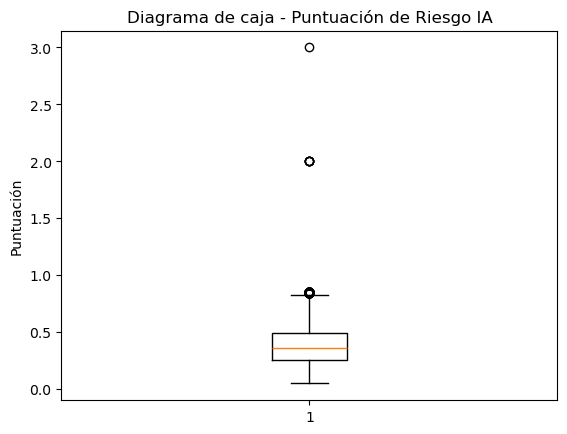

In [50]:
# Diagrama de caja de la variable puntuacion_riesgo_ia
import matplotlib.pyplot as plt

plt.boxplot(df1['puntuacion_riesgo_ia'])
plt.title('Diagrama de caja - Puntuación de Riesgo IA')
plt.ylabel('Puntuación')
plt.show()

In [51]:
# valores unicos de la variable puntuacion_riesgo_ia
df1['puntuacion_riesgo_ia'].unique()

array([0.32      , 0.52      , 0.25      , 0.44      , 0.75      ,
       0.38      , 0.28      , 0.35      , 0.36      , 0.39      ,
       0.37      , 0.33      , 0.42      , 0.27      , 2.        ,
       0.43      , 0.21      , 0.55      , 0.72      , 0.12      ,
       0.16      , 0.49      , 0.65      , 0.45      , 3.        ,
       0.73      , 0.4       , 0.31      , 0.26      , 0.5       ,
       0.11      , 0.53      , 0.2       , 0.41      , 0.71      ,
       0.06      , 0.82      , 0.7       , 0.19      , 0.56      ,
       0.15      , 0.67      , 0.24      , 0.34      , 0.47      ,
       0.23      , 0.29      , 0.51      , 0.85      , 0.59      ,
       0.62      , 0.68      , 0.3       , 0.09      , 0.81      ,
       0.17      , 0.6       , 0.22      , 0.18      , 0.05      ,
       0.66      , 0.74      , 0.54      , 0.77      , 0.46      ,
       0.78      , 0.48      , 0.1       , 0.8       , 0.69      ,
       0.64      , 0.61      , 0.84      , 0.57      , 0.79   

# Tratar la variable "puntuacion_riesgo_ia"

In [52]:
# 1. Copia de respaldo de la variable original
df1["puntuacion_riesgo_ia_original"] = df1["puntuacion_riesgo_ia"]

# 2. Definir la máscara para mantener solo valores en el rango [0, 1] (mayores a 1 pasan a ser False)
mask_valido = (df1["puntuacion_riesgo_ia"] >= 0) & (df1["puntuacion_riesgo_ia"] <= 1)

# 3. Aplicar np.where: si cumple la condición conserva el valor, si es mayor a 1 (o menor a 0) asigna NaN
df1["puntuacion_riesgo_ia_clean"] = np.where(
    mask_valido, df1["puntuacion_riesgo_ia"], np.nan
)

# 4. Verificar la conversión de los valores nulos (outliers)
print("Valores nulos/atípicos detectados (> 1):", df1["puntuacion_riesgo_ia_clean"].isna().sum())
print(df1[["puntuacion_riesgo_ia_original", "puntuacion_riesgo_ia_clean"]].head(10))

Valores nulos/atípicos detectados (> 1): 6
   puntuacion_riesgo_ia_original  puntuacion_riesgo_ia_clean
0                           0.32                        0.32
1                           0.52                        0.52
2                           0.25                        0.25
3                           0.44                        0.44
4                           0.75                        0.75
5                           0.38                        0.38
6                           0.28                        0.28
7                           0.35                        0.35
8                           0.36                        0.36
9                           0.39                        0.39


In [53]:
# Mostrar filas donde la variable original era > 1 para validar la transformación a NaN
filas_atipicas = df1[df1["puntuacion_riesgo_ia_original"] > 1]
print("=== MUESTRA DE REGISTROS TRANSFORMADOS A NaN ===")
print(filas_atipicas[["puntuacion_riesgo_ia_original", "puntuacion_riesgo_ia_clean"]].head())

=== MUESTRA DE REGISTROS TRANSFORMADOS A NaN ===
     puntuacion_riesgo_ia_original  puntuacion_riesgo_ia_clean
14                             2.0                         NaN
30                             3.0                         NaN
426                            2.0                         NaN
427                            2.0                         NaN
428                            2.0                         NaN


In [54]:
df1 ["puntuacion_riesgo_ia_clean"].unique()

array([0.32      , 0.52      , 0.25      , 0.44      , 0.75      ,
       0.38      , 0.28      , 0.35      , 0.36      , 0.39      ,
       0.37      , 0.33      , 0.42      , 0.27      ,        nan,
       0.43      , 0.21      , 0.55      , 0.72      , 0.12      ,
       0.16      , 0.49      , 0.65      , 0.45      , 0.73      ,
       0.4       , 0.31      , 0.26      , 0.5       , 0.11      ,
       0.53      , 0.2       , 0.41      , 0.71      , 0.06      ,
       0.82      , 0.7       , 0.19      , 0.56      , 0.15      ,
       0.67      , 0.24      , 0.34      , 0.47      , 0.23      ,
       0.29      , 0.51      , 0.85      , 0.59      , 0.62      ,
       0.68      , 0.3       , 0.09      , 0.81      , 0.17      ,
       0.6       , 0.22      , 0.18      , 0.05      , 0.66      ,
       0.74      , 0.54      , 0.77      , 0.46      , 0.78      ,
       0.48      , 0.1       , 0.8       , 0.69      , 0.64      ,
       0.61      , 0.84      , 0.57      , 0.79      , 0.07   

In [55]:
# Imputación por la mediana agrupada por título de puesto
df1["puntuacion_riesgo_ia_clean"] = df1["puntuacion_riesgo_ia_clean"].fillna(
    df1.groupby("titulo_puesto")["puntuacion_riesgo_ia_clean"].transform(
        "median"
    )
)

## Imputación por la mediana agrupada por título de puesto

En este paso, los valores faltantes de `puntuacion_riesgo_ia_clean` se reemplazan con la **mediana de los valores válidos correspondientes al mismo `titulo_puesto`**.

La mediana es menos sensible a los valores extremos que la media. Agrupar por título también permite que la imputación refleje las diferencias entre puestos, en vez de usar una única mediana para todo el conjunto.

Los valores que ya existen se conservan. Si para algún título todos los valores están ausentes, no se puede calcular su mediana y esos casos seguirán siendo `NaN`; conviene verificarlos después de la imputación.

In [56]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12425 entries, 0 to 12424
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   titulo_puesto                  12425 non-null  object 
 1   pais                           12425 non-null  object 
 2   nivel_experiencia              12425 non-null  object 
 3   nivel_educacion                12425 non-null  object 
 4   año                            12425 non-null  float64
 5   salario                        12425 non-null  float64
 6   puntuacion_riesgo_ia           12425 non-null  float64
 7   habilidad_principal            12425 non-null  object 
 8   puntuacion_demanda_habilidad   12425 non-null  float64
 9   vacantes_laborales             12425 non-null  float64
 10  clase_supervivencia_puesto     12425 non-null  float64
 11  categoria_salario              12425 non-null  object 
 12  categoria_riesgo_ia            12425 non-null 

In [57]:
# contar valores NAN de la variable puntuacion_riesgo_ia
print(df1["puntuacion_riesgo_ia_clean"].isnull().sum())

0


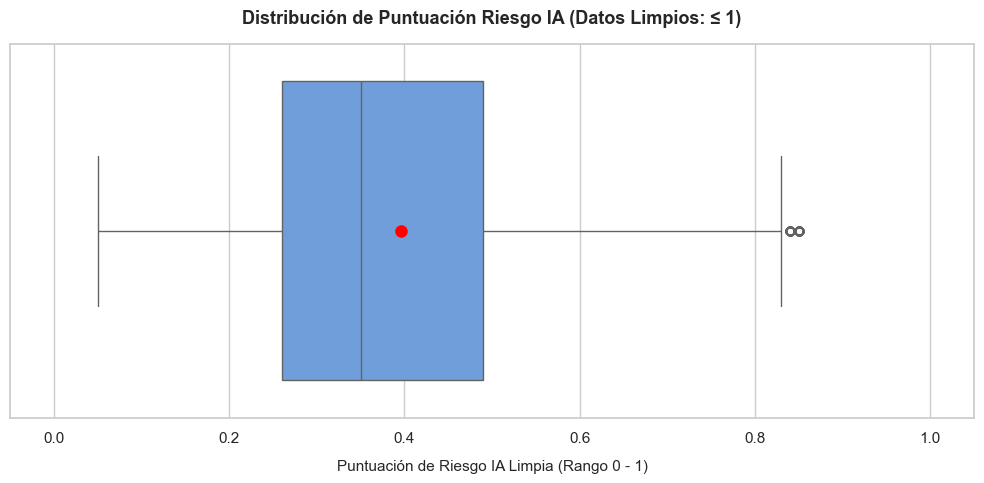

In [58]:
# 1. Configuración de estilo y tamaño de la figura
plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")

# 2. Creación del diagrama de caja (Boxplot)
ax = sns.boxplot(
    x=df1["puntuacion_riesgo_ia_clean"],
    color="#5D9CEC",  # Color azul claro
    showmeans=True,  # Mostrar la media (promedio)
    meanprops={
        "marker": "o",
        "markerfacecolor": "red",
        "markeredgecolor": "red",
        "markersize": 8,
    },
)

# 3. Personalización de títulos y límites del eje X
plt.title(
    "Distribución de Puntuación Riesgo IA (Datos Limpios: ≤ 1)",
    fontsize=13,
    pad=15,
    fontweight="bold",
)
plt.xlabel(
    "Puntuación de Riesgo IA Limpia (Rango 0 - 1)", fontsize=11, labelpad=10
)
plt.xlim(-0.05, 1.05)

# 4. Ajustar el diseño y desplegar
plt.tight_layout()
plt.show()


In [59]:
# Analizar la varible: vacantes_laborales que esta df1...

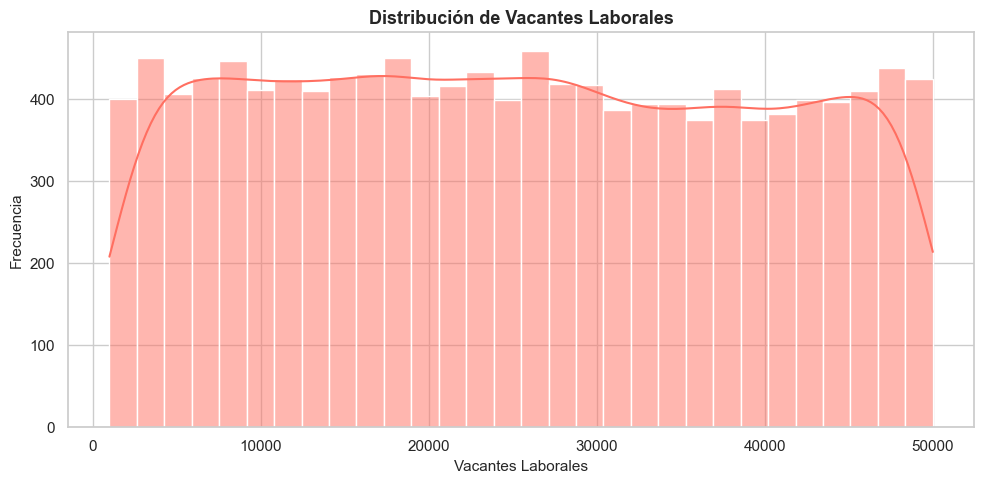

In [60]:
# grafica de distribución de la variable: vacantes_laborales
plt.figure(figsize=(10, 5))
sns.histplot(df1["vacantes_laborales"], bins=30, kde=True, color="#FF6F61")
plt.title("Distribución de Vacantes Laborales", fontsize=13, fontweight="bold")
plt.xlabel("Vacantes Laborales", fontsize=11)
plt.ylabel("Frecuencia", fontsize=11)
plt.tight_layout()
plt.show()


In [61]:
# Identificar outliers usando el metodo zscore
# importar la función zscore de scipy.stats
from scipy.stats import zscore 

In [62]:
# 2. Definir la variable y calcular la Media y Desviación Estándar
columna = "vacantes_laborales"
media = df1[columna].mean()
desviacion_std = df1[columna].std()

# 3. Calcular la Puntuación Z (Z-score) de cada registro
df1["z_score_vacantes"] = (df1[columna] - media) / desviacion_std

# 4. Filtrar valores atípicos considerando un umbral de |Z| > 3
umbral = 3
mask_atipicos = np.abs(df1["z_score_vacantes"]) > umbral

# DataFrames separados: excluidos vs conservados
df_excluidos = df1[mask_atipicos]
df_limpio = df1[~mask_atipicos]

# 5. Mostrar resultados y diagnóstico
print("=== RESUMEN DEL MÉTODO Z-SCORE ===")
print(f"Total de registros analizados: {len(df1)}")
print(
    f"Valores atípicos detectados/excluidos (|Z| > {umbral}): {len(df_excluidos)}"
)
print(f"Registros conservados: {len(df_limpio)}\n")

# 6. Desplegar los datos excluidos
if len(df_excluidos) > 0:
    print("=== MUESTRA DE REGISTROS EXCLUIDOS ===")
    print(df_excluidos[[columna, "z_score_vacantes"]].head())
else:
    print(
        f" No se encontraron valores atípicos fuera del umbral |Z| > {umbral} para '{columna}'."
    )

=== RESUMEN DEL MÉTODO Z-SCORE ===
Total de registros analizados: 12425
Valores atípicos detectados/excluidos (|Z| > 3): 0
Registros conservados: 12425

 No se encontraron valores atípicos fuera del umbral |Z| > 3 para 'vacantes_laborales'.


In [63]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12425 entries, 0 to 12424
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   titulo_puesto                  12425 non-null  object 
 1   pais                           12425 non-null  object 
 2   nivel_experiencia              12425 non-null  object 
 3   nivel_educacion                12425 non-null  object 
 4   año                            12425 non-null  float64
 5   salario                        12425 non-null  float64
 6   puntuacion_riesgo_ia           12425 non-null  float64
 7   habilidad_principal            12425 non-null  object 
 8   puntuacion_demanda_habilidad   12425 non-null  float64
 9   vacantes_laborales             12425 non-null  float64
 10  clase_supervivencia_puesto     12425 non-null  float64
 11  categoria_salario              12425 non-null  object 
 12  categoria_riesgo_ia            12425 non-null 


==================================================================================

# Rango intercuartil (RIQ o IQR)

- La regla del 1,5 veces el rango intercuartílico (RIC) determina que cualquier dato que se encuentre 1,5 veces por debajo del primer cuartil o por encima del tercer cuartil es un valor atípico. 
- El método del rango intercuartílico (RIC) para la detección de valores atípicos establece que cualquier punto de datos en un diagrama de caja que se encuentre a más de 1,5 RIC por debajo del primer cuartil o a más de 1,5 RIC por encima del tercer cuartil se considera un valor atípico.
- Es una medida de dispersión que se utiliza junto con la mediana (en lugar de la media) cuando se analizan conjuntos de datos, especialmente aquellos que están **sesgados** o contienen **valores atípicos (outliers)**.

## El **rango intercuartil (RIQ o IQR)** trabaja principalmente con la **mediana**.
---

## ¿Por qué trabaja con la mediana?

### Robustez
El RIQ mide la dispersión del **50% central de los datos**, es decir, la diferencia entre:
- el **tercer cuartil (Q3)**
- el **primer cuartil (Q1)**

---

### Distribuciones asimétricas
Cuando la distribución de los datos no es simétrica, la **mediana** es la mejor medida de tendencia central.  
En estos casos, el RIQ es la medida de variabilidad correspondiente.

---

### Independencia de valores extremos
Al igual que la mediana, el RIQ **no se ve afectado significativamente por valores extremos**, a diferencia de:
- la media
- la desviación estándar

---

## Importante
En estadística, para datos no normales o con outliers, la combinación estándar es:

> **Mediana + Rango Intercuartil (RIQ)**

In [64]:
# aplica el metodo Rango intercuartil (RIQ o IQR) a la variable "salario"

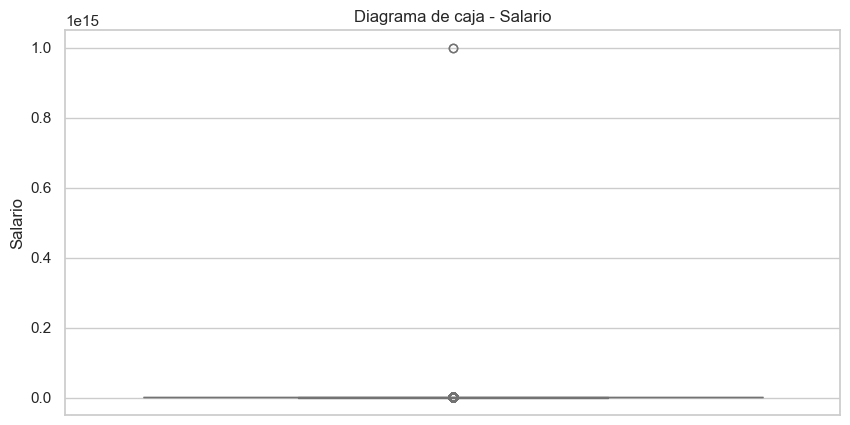

In [65]:
# graficar diagrama de caja para la variable "salario"
plt.figure(figsize=(10, 5))
sns.boxplot(y=df1["salario"], color="lightgreen")
plt.title("Diagrama de caja - Salario")
plt.ylabel("Salario")
plt.show()  

In [66]:
# estadistica descriptiva de la variable "salario"
df1["salario"].describe()

count    1.242500e+04
mean     1.610722e+11
std      1.268672e+13
min      3.875170e+03
25%      2.136399e+04
50%      3.158789e+04
75%      4.533056e+04
max      1.000000e+15
Name: salario, dtype: float64

In [67]:
# Seleccionar la variable y excluir los valores nulos del cálculo
salario = df1["salario"].dropna()

# Calcular los cuartiles
Q1 = salario.quantile(0.25)
Q3 = salario.quantile(0.75)

# Calcular el rango intercuartílico
IQR = Q3 - Q1

# Calcular los límites para detectar posibles valores atípicos
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Identificar posibles valores atípicos
mascara_outliers = (
    (df1["salario"] < limite_inferior) |
    (df1["salario"] > limite_superior)
)

print(f"Q1: {Q1:,.2f}")
print(f"Q3: {Q3:,.2f}")
print(f"IQR: {IQR:,.2f}")
print(f"Límite inferior: {limite_inferior:,.2f}")
print(f"Límite superior: {limite_superior:,.2f}")
print(f"Posibles outliers: {mascara_outliers.sum():,}")
print(f"Porcentaje de outliers: {mascara_outliers.mean() * 100:.2f}%")

Q1: 21,363.99
Q3: 45,330.56
IQR: 23,966.57
Límite inferior: -14,585.86
Límite superior: 81,280.41
Posibles outliers: 195
Porcentaje de outliers: 1.57%


In [68]:
# Mostrar los 20 salarios más altos
print(
    df1.nlargest(20, "salario")[["salario"]]
)

# Inspeccionar las filas con posibles outliers
outliers = df1.loc[mascara_outliers].sort_values(
    by="salario",
    ascending=False
)

display(outliers.head(20))

            salario
3605   1.000000e+15
3611   1.000000e+15
3587   1.000000e+12
12390  1.610722e+11
12391  1.610722e+11
949    1.135893e+05
10979  1.069147e+05
12399  1.069147e+05
196    1.068964e+05
12279  1.065178e+05
7307   1.064274e+05
10367  1.062497e+05
6370   1.057454e+05
5268   1.054560e+05
5120   1.045958e+05
9327   1.036928e+05
9381   1.036490e+05
7998   1.031048e+05
8927   1.026041e+05
1266   1.019563e+05


,titulo_puesto,pais,nivel_experiencia,nivel_educacion,año,salario,puntuacion_riesgo_ia,habilidad_principal,puntuacion_demanda_habilidad,vacantes_laborales,clase_supervivencia_puesto,categoria_salario,categoria_riesgo_ia,puntuacion_riesgo_ia_original,puntuacion_riesgo_ia_clean,z_score_vacantes
3611,Analista de Negocios,India,Intermedio,Maestria,2015.000000,1.000000e+15,0.650000,Excel,67.000000,12085.000000,0.000000,Bajo,Riesgo Alto,0.650000,0.650000,-0.927481
3605,Ingeniero Cloud,India,Inicial,Maestria,2027.000000,1.000000e+15,0.370000,AWS,84.000000,48904.000000,1.000000,Bajo,Riesgo Medio,0.370000,0.370000,1.672498
3587,Ingeniero de Software,Reino Unido,Intermedio,Maestria,2022.000000,1.000000e+12,0.420000,Java,77.000000,33126.000000,1.000000,Alto,Riesgo Medio,0.420000,0.420000,0.558332
12391,Analista de Negocios,Reino Unido,Senior,Maestria,2025.059728,1.610722e+11,0.396858,Python,79.458746,25219.309668,1.310151,Alto,Riesgo Medio,0.396858,0.396858,0.000000
12390,Analista de Negocios,Reino Unido,Senior,Maestria,2025.059728,1.610722e+11,0.396858,Python,79.458746,25219.309668,1.310151,Alto,Riesgo Medio,0.396858,0.396858,0.000000
949,Investigador de IA,EE. UU.,Senior,Doctorado,2034.000000,1.135893e+05,0.240000,Deep Learning,95.000000,17977.000000,2.000000,Alto,Riesgo Bajo,0.240000,0.240000,-0.511417
12399,Investigador de IA,EE. UU.,Senior,Doctorado,2034.000000,1.069147e+05,0.240000,Deep Learning,83.000000,39809.000000,2.000000,Alto,Riesgo Bajo,0.240000,0.240000,1.030253
10979,Investigador de IA,EE. UU.,Senior,Doctorado,2034.000000,1.069147e+05,0.240000,Deep Learning,83.000000,39809.000000,2.000000,Alto,Riesgo Bajo,0.240000,0.240000,1.030253
196,Investigador de IA,EE. UU.,Senior,Licenciatura,2035.000000,1.068964e+05,0.250000,Deep Learning,83.000000,1667.000000,2.000000,Alto,Riesgo Bajo,0.250000,0.250000,-1.663150
12279,Investigador de IA,EE. UU.,Senior,Licenciatura,2030.000000,1.065178e+05,0.200000,Deep Learning,62.000000,11188.000000,2.000000,Alto,Riesgo Bajo,0.200000,0.200000,-0.990823


In [69]:
# Revisar los 15 salarios más altos y sus variables asociadas
columnas_revision = [
    "titulo_puesto",
    "pais",
    "nivel_experiencia",
    "a�o_",
    "salario",
    "categoria_salario"
]

columnas_revision = [
    "titulo_puesto",
    "pais",
    "nivel_experiencia",
    "año",
    "salario",
    "categoria_salario"
]

display(df1.nlargest(15, "salario")[columnas_revision])

# Comprobar cuántos salarios son extremadamente grandes
for umbral in [1_000_000, 1_000_000_000, 1_000_000_000_000]:
    cantidad = (df1["salario"] > umbral).sum()
    print(f"Salarios superiores a {umbral:,.0f}: {cantidad}")

,titulo_puesto,pais,nivel_experiencia,año,salario,categoria_salario
3605,Ingeniero Cloud,India,Inicial,2027.000000,1.000000e+15,Bajo
3611,Analista de Negocios,India,Intermedio,2015.000000,1.000000e+15,Bajo
3587,Ingeniero de Software,Reino Unido,Intermedio,2022.000000,1.000000e+12,Alto
12390,Analista de Negocios,Reino Unido,Senior,2025.059728,1.610722e+11,Alto
12391,Analista de Negocios,Reino Unido,Senior,2025.059728,1.610722e+11,Alto
949,Investigador de IA,EE. UU.,Senior,2034.000000,1.135893e+05,Alto
10979,Investigador de IA,EE. UU.,Senior,2034.000000,1.069147e+05,Alto
12399,Investigador de IA,EE. UU.,Senior,2034.000000,1.069147e+05,Alto
196,Investigador de IA,EE. UU.,Senior,2035.000000,1.068964e+05,Alto
12279,Investigador de IA,EE. UU.,Senior,2030.000000,1.065178e+05,Alto


Salarios superiores a 1,000,000: 5
Salarios superiores a 1,000,000,000: 5
Salarios superiores a 1,000,000,000,000: 2


In [70]:
# 1. Duplicados exactos en todas las columnas
duplicados_exactos = df1.duplicated(keep=False)

print("Filas que forman parte de duplicados exactos:",
      duplicados_exactos.sum())

# 2. Inspeccionar los registros de interés
display(df1.loc[[12390, 12391]])

# 3. Revisar si existen filas idénticas en las columnas principales
columnas_clave = [
    "titulo_puesto",
    "pais",
    "nivel_experiencia",
    "nivel_educacion",
    "salario"
]

duplicados_clave = df1.duplicated(
    subset=columnas_clave,
    keep=False
)

print("Filas duplicadas según las columnas clave:",
      duplicados_clave.sum())

Filas que forman parte de duplicados exactos: 156


,titulo_puesto,pais,nivel_experiencia,nivel_educacion,año,salario,puntuacion_riesgo_ia,habilidad_principal,puntuacion_demanda_habilidad,vacantes_laborales,clase_supervivencia_puesto,categoria_salario,categoria_riesgo_ia,puntuacion_riesgo_ia_original,puntuacion_riesgo_ia_clean,z_score_vacantes
12390,Analista de Negocios,Reino Unido,Senior,Maestria,2025.059728,1.610722e+11,0.396858,Python,79.458746,25219.309668,1.310151,Alto,Riesgo Medio,0.396858,0.396858,0.0
12391,Analista de Negocios,Reino Unido,Senior,Maestria,2025.059728,1.610722e+11,0.396858,Python,79.458746,25219.309668,1.310151,Alto,Riesgo Medio,0.396858,0.396858,0.0


Filas duplicadas según las columnas clave: 156


In [71]:
# Examinar las categorías asociadas a los salarios extremos
display(
    df1.loc[mascara_outliers, [
        "salario",
        "categoria_salario",
        "pais",
        "titulo_puesto"
    ]].sort_values("salario", ascending=False).head(30)
)

# Resumen numérico de salario por categoría
print(
    df1.groupby("categoria_salario", dropna=False)["salario"]
       .agg(["count", "min", "median", "max"])
)

,salario,categoria_salario,pais,titulo_puesto
3611,1.000000e+15,Bajo,India,Analista de Negocios
3605,1.000000e+15,Bajo,India,Ingeniero Cloud
3587,1.000000e+12,Alto,Reino Unido,Ingeniero de Software
12391,1.610722e+11,Alto,Reino Unido,Analista de Negocios
12390,1.610722e+11,Alto,Reino Unido,Analista de Negocios
949,1.135893e+05,Alto,EE. UU.,Investigador de IA
12399,1.069147e+05,Alto,EE. UU.,Investigador de IA
10979,1.069147e+05,Alto,EE. UU.,Investigador de IA
196,1.068964e+05,Alto,EE. UU.,Investigador de IA
12279,1.065178e+05,Alto,EE. UU.,Investigador de IA


                   count       min     median           max
categoria_salario                                          
Alto                9668  20002.90  36926.100  1.000000e+12
Bajo                 646   3875.17   7981.345  1.000000e+15
Medio               2111  10004.10  15587.660  1.999961e+04


In [72]:
# Comprobar duplicados exactos en todas las columnas
n_duplicados_exactos = df1.duplicated(keep=False).sum()

# Contar filas que son copias posteriores de otra fila
n_copias_exactas = df1.duplicated().sum()

print("Filas involucradas en duplicados exactos:",
      n_duplicados_exactos)

print("Copias exactas adicionales:",
      n_copias_exactas)

# Mostrar las filas exactas duplicadas
display(
    df1.loc[df1.duplicated(keep=False)]
       .sort_values("salario", ascending=False)
       .head(20)
)

Filas involucradas en duplicados exactos: 156
Copias exactas adicionales: 78


,titulo_puesto,pais,nivel_experiencia,nivel_educacion,año,salario,puntuacion_riesgo_ia,habilidad_principal,puntuacion_demanda_habilidad,vacantes_laborales,clase_supervivencia_puesto,categoria_salario,categoria_riesgo_ia,puntuacion_riesgo_ia_original,puntuacion_riesgo_ia_clean,z_score_vacantes
12391,Analista de Negocios,Reino Unido,Senior,Maestria,2025.059728,1.610722e+11,0.396858,Python,79.458746,25219.309668,1.310151,Alto,Riesgo Medio,0.396858,0.396858,0.000000
12390,Analista de Negocios,Reino Unido,Senior,Maestria,2025.059728,1.610722e+11,0.396858,Python,79.458746,25219.309668,1.310151,Alto,Riesgo Medio,0.396858,0.396858,0.000000
10979,Investigador de IA,EE. UU.,Senior,Doctorado,2034.000000,1.069147e+05,0.240000,Deep Learning,83.000000,39809.000000,2.000000,Alto,Riesgo Bajo,0.240000,0.240000,1.030253
12399,Investigador de IA,EE. UU.,Senior,Doctorado,2034.000000,1.069147e+05,0.240000,Deep Learning,83.000000,39809.000000,2.000000,Alto,Riesgo Bajo,0.240000,0.240000,1.030253
12372,Ingeniero de ML,EE. UU.,Senior,Doctorado,2031.000000,9.447111e+04,0.310000,Python,68.000000,7477.000000,2.000000,Alto,Riesgo Medio,0.310000,0.310000,-1.252876
1780,Ingeniero de ML,EE. UU.,Senior,Doctorado,2031.000000,9.447111e+04,0.310000,Python,68.000000,7477.000000,2.000000,Alto,Riesgo Medio,0.310000,0.310000,-1.252876
12351,Ingeniero DevOps,EE. UU.,Senior,Licenciatura,2032.000000,7.884045e+04,0.370000,Docker,79.000000,20553.000000,2.000000,Alto,Riesgo Medio,0.370000,0.370000,-0.329512
12071,Ingeniero DevOps,EE. UU.,Senior,Licenciatura,2032.000000,7.884045e+04,0.370000,Docker,79.000000,20553.000000,2.000000,Alto,Riesgo Medio,0.370000,0.370000,-0.329512
12366,Gerente de Producto,EE. UU.,Senior,Maestria,2023.000000,7.849286e+04,0.380000,Estrategia,88.000000,16310.000000,2.000000,Alto,Riesgo Medio,0.380000,0.380000,-0.629132
1774,Gerente de Producto,EE. UU.,Senior,Maestria,2023.000000,7.849286e+04,0.380000,Estrategia,88.000000,16310.000000,2.000000,Alto,Riesgo Medio,0.380000,0.380000,-0.629132


In [73]:
# Resumen del salario por categoría
resumen_categorias = (
    df1.groupby("categoria_salario")["salario"]
       .agg(
           registros="count",
           minimo="min",
           percentil_25=lambda x: x.quantile(0.25),
           mediana="median",
           percentil_75=lambda x: x.quantile(0.75),
           maximo="max"
       )
       .round(2)
)

display(resumen_categorias)

# Mostrar los salarios extremos por categoría
display(
    df1.sort_values("salario", ascending=False)[
        ["salario", "categoria_salario", "titulo_puesto", "pais"]
    ].head(20)
)

,registros,minimo,percentil_25,mediana,percentil_75,maximo
categoria_salario,,,,,,
Alto,9668,20002.90,27934.84,36926.10,49483.83,1.000000e+12
Bajo,646,3875.17,6732.27,7981.34,9113.78,1.000000e+15
Medio,2111,10004.10,12930.36,15587.66,17929.93,1.999961e+04


,salario,categoria_salario,titulo_puesto,pais
3605,1.000000e+15,Bajo,Ingeniero Cloud,India
3611,1.000000e+15,Bajo,Analista de Negocios,India
3587,1.000000e+12,Alto,Ingeniero de Software,Reino Unido
12391,1.610722e+11,Alto,Analista de Negocios,Reino Unido
12390,1.610722e+11,Alto,Analista de Negocios,Reino Unido
949,1.135893e+05,Alto,Investigador de IA,EE. UU.
12399,1.069147e+05,Alto,Investigador de IA,EE. UU.
10979,1.069147e+05,Alto,Investigador de IA,EE. UU.
196,1.068964e+05,Alto,Investigador de IA,EE. UU.
12279,1.065178e+05,Alto,Investigador de IA,EE. UU.


In [74]:
# Contar salarios por encima de umbrales de diagnóstico
umbrales = [100_000, 1_000_000, 1_000_000_000]

for umbral in umbrales:
    mascara = df1["salario"] > umbral

    print(f"\nSalario superior a {umbral:,.0f}")
    print("Número de filas:", int(mascara.sum()))

    display(
        df1.loc[
            mascara,
            ["salario", "categoria_salario",
             "titulo_puesto", "pais", "nivel_experiencia"]
        ].head(10)
    )


Salario superior a 100,000
Número de filas: 27


,salario,categoria_salario,titulo_puesto,pais,nivel_experiencia
196,1.068964e+05,Alto,Investigador de IA,EE. UU.,Senior
949,1.135893e+05,Alto,Investigador de IA,EE. UU.,Senior
1266,1.019563e+05,Alto,Ingeniero de ML,EE. UU.,Senior
2540,1.000947e+05,Alto,Investigador de IA,EE. UU.,Senior
3359,1.017937e+05,Alto,Investigador de IA,EE. UU.,Senior
3552,1.011336e+05,Alto,Ingeniero de ML,EE. UU.,Senior
3587,1.000000e+12,Alto,Ingeniero de Software,Reino Unido,Intermedio
3605,1.000000e+15,Bajo,Ingeniero Cloud,India,Inicial
3611,1.000000e+15,Bajo,Analista de Negocios,India,Intermedio
5120,1.045958e+05,Alto,Ingeniero de ML,EE. UU.,Senior



Salario superior a 1,000,000
Número de filas: 5


,salario,categoria_salario,titulo_puesto,pais,nivel_experiencia
3587,1.000000e+12,Alto,Ingeniero de Software,Reino Unido,Intermedio
3605,1.000000e+15,Bajo,Ingeniero Cloud,India,Inicial
3611,1.000000e+15,Bajo,Analista de Negocios,India,Intermedio
12390,1.610722e+11,Alto,Analista de Negocios,Reino Unido,Senior
12391,1.610722e+11,Alto,Analista de Negocios,Reino Unido,Senior



Salario superior a 1,000,000,000
Número de filas: 5


,salario,categoria_salario,titulo_puesto,pais,nivel_experiencia
3587,1.000000e+12,Alto,Ingeniero de Software,Reino Unido,Intermedio
3605,1.000000e+15,Bajo,Ingeniero Cloud,India,Inicial
3611,1.000000e+15,Bajo,Analista de Negocios,India,Intermedio
12390,1.610722e+11,Alto,Analista de Negocios,Reino Unido,Senior
12391,1.610722e+11,Alto,Analista de Negocios,Reino Unido,Senior


## ¿Qué son los umbrales y por qué importan?

Un **umbral** es un valor de referencia que se usa para separar o identificar registros según una condición. Por ejemplo, `salario > 100_000` selecciona los salarios superiores a 100.000.

Considerar los umbrales es importante porque ayuda a:

- Detectar valores extremos o posibles errores.
- Definir límites para clasificar o filtrar datos.
- Interpretar los resultados según el contexto y las unidades de la variable.
- Evitar decisiones automáticas que eliminen datos válidos.

En este análisis, el **límite superior del IQR** es un umbral estadístico para señalar posibles valores atípicos. En cambio, un umbral como `1_000_000` puede servir para localizar salarios excepcionalmente altos y revisarlos. Estos límites indican qué datos investigar; **no demuestran por sí solos que sean errores ni que deban eliminarse**.

In [75]:
# Identificar los salarios extremadamente elevados
columnas = [
    "titulo_puesto",
    "pais",
    "nivel_experiencia",
    "nivel_educacion",
    "a�o_",
    "salario",
    "categoria_salario"
]

# Identificar los salarios extremadamente elevados
columnas = [
    "titulo_puesto",
    "pais",
    "nivel_experiencia",
    "nivel_educacion",
    "año",
    "salario",
    "categoria_salario"
]

casos_extremos = (
    df1.loc[df1["salario"] > 1_000_000, columnas]
       .sort_values("salario", ascending=False)
)

display(casos_extremos)

# Mostrar los casos que superan 100.000
casos_altos = (
    df1.loc[df1["salario"] > 100_000, columnas]
       .sort_values("salario", ascending=False)
)

display(casos_altos)

display(casos_extremos)

# Mostrar los 27 casos que superan 100.000
casos_altos = (
    df1.loc[df1["salario"] > 100_000, columnas]
       .sort_values("salario", ascending=False)
)

display(casos_altos)

,titulo_puesto,pais,nivel_experiencia,nivel_educacion,año,salario,categoria_salario
3605,Ingeniero Cloud,India,Inicial,Maestria,2027.000000,1.000000e+15,Bajo
3611,Analista de Negocios,India,Intermedio,Maestria,2015.000000,1.000000e+15,Bajo
3587,Ingeniero de Software,Reino Unido,Intermedio,Maestria,2022.000000,1.000000e+12,Alto
12390,Analista de Negocios,Reino Unido,Senior,Maestria,2025.059728,1.610722e+11,Alto
12391,Analista de Negocios,Reino Unido,Senior,Maestria,2025.059728,1.610722e+11,Alto


,titulo_puesto,pais,nivel_experiencia,nivel_educacion,año,salario,categoria_salario
3611,Analista de Negocios,India,Intermedio,Maestria,2015.000000,1.000000e+15,Bajo
3605,Ingeniero Cloud,India,Inicial,Maestria,2027.000000,1.000000e+15,Bajo
3587,Ingeniero de Software,Reino Unido,Intermedio,Maestria,2022.000000,1.000000e+12,Alto
12391,Analista de Negocios,Reino Unido,Senior,Maestria,2025.059728,1.610722e+11,Alto
12390,Analista de Negocios,Reino Unido,Senior,Maestria,2025.059728,1.610722e+11,Alto
949,Investigador de IA,EE. UU.,Senior,Doctorado,2034.000000,1.135893e+05,Alto
12399,Investigador de IA,EE. UU.,Senior,Doctorado,2034.000000,1.069147e+05,Alto
10979,Investigador de IA,EE. UU.,Senior,Doctorado,2034.000000,1.069147e+05,Alto
196,Investigador de IA,EE. UU.,Senior,Licenciatura,2035.000000,1.068964e+05,Alto
12279,Investigador de IA,EE. UU.,Senior,Licenciatura,2030.000000,1.065178e+05,Alto


,titulo_puesto,pais,nivel_experiencia,nivel_educacion,año,salario,categoria_salario
3605,Ingeniero Cloud,India,Inicial,Maestria,2027.000000,1.000000e+15,Bajo
3611,Analista de Negocios,India,Intermedio,Maestria,2015.000000,1.000000e+15,Bajo
3587,Ingeniero de Software,Reino Unido,Intermedio,Maestria,2022.000000,1.000000e+12,Alto
12390,Analista de Negocios,Reino Unido,Senior,Maestria,2025.059728,1.610722e+11,Alto
12391,Analista de Negocios,Reino Unido,Senior,Maestria,2025.059728,1.610722e+11,Alto


,titulo_puesto,pais,nivel_experiencia,nivel_educacion,año,salario,categoria_salario
3611,Analista de Negocios,India,Intermedio,Maestria,2015.000000,1.000000e+15,Bajo
3605,Ingeniero Cloud,India,Inicial,Maestria,2027.000000,1.000000e+15,Bajo
3587,Ingeniero de Software,Reino Unido,Intermedio,Maestria,2022.000000,1.000000e+12,Alto
12391,Analista de Negocios,Reino Unido,Senior,Maestria,2025.059728,1.610722e+11,Alto
12390,Analista de Negocios,Reino Unido,Senior,Maestria,2025.059728,1.610722e+11,Alto
949,Investigador de IA,EE. UU.,Senior,Doctorado,2034.000000,1.135893e+05,Alto
12399,Investigador de IA,EE. UU.,Senior,Doctorado,2034.000000,1.069147e+05,Alto
10979,Investigador de IA,EE. UU.,Senior,Doctorado,2034.000000,1.069147e+05,Alto
196,Investigador de IA,EE. UU.,Senior,Licenciatura,2035.000000,1.068964e+05,Alto
12279,Investigador de IA,EE. UU.,Senior,Licenciatura,2030.000000,1.065178e+05,Alto


In [76]:
# Trabajar sobre una copia del DataFrame original
df1_limpio = df1.copy()

# Calcular cuartiles ignorando valores nulos
Q1 = df1_limpio["salario"].quantile(0.25)
Q3 = df1_limpio["salario"].quantile(0.75)

# Calcular el rango intercuartílico
IQR = Q3 - Q1

# Definir los límites para detectar valores atípicos
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"Q1: {Q1:,.2f}")
print(f"Q3: {Q3:,.2f}")
print(f"IQR: {IQR:,.2f}")
print(f"Límite inferior: {limite_inferior:,.2f}")
print(f"Límite superior: {limite_superior:,.2f}")

Q1: 21,363.99
Q3: 45,330.56
IQR: 23,966.57
Límite inferior: -14,585.86
Límite superior: 81,280.41


In [77]:
# Número de filas antes de la limpieza
filas_originales = len(df1_limpio)

# Identificar salarios atípicos
mascara_outliers = (
    (df1_limpio["salario"] < limite_inferior) |
    (df1_limpio["salario"] > limite_superior)
)

# Contar los registros que serán eliminados
n_outliers = int(mascara_outliers.sum())

# Eliminar los registros atípicos y conservar los nulos
df1_limpio = df1_limpio.loc[
    ~mascara_outliers
].copy()

# Resumen de la operación
print(f"Filas originales: {filas_originales:,}")
print(f"Filas eliminadas: {n_outliers:,}")
print(f"Filas restantes: {len(df1_limpio):,}")

Filas originales: 12,425
Filas eliminadas: 195
Filas restantes: 12,230


In [78]:
# Estadísticas después de eliminar los outliers
display(df1_limpio["salario"].describe())

# Verificar los límites observados en el DataFrame resultante
print("Salario mínimo:", df1_limpio["salario"].min())
print("Salario máximo:", df1_limpio["salario"].max())

# Comprobar que no queden valores fuera de los límites originales
outliers_restantes = (
    (df1_limpio["salario"] < limite_inferior) |
    (df1_limpio["salario"] > limite_superior)
).sum()

print("Outliers restantes según los límites calculados:",
      outliers_restantes)

count    12230.000000
mean     33710.275295
std      16755.490670
min       3875.170000
25%      21180.460000
50%      31237.580000
75%      44419.350000
max      81279.590000
Name: salario, dtype: float64

Salario mínimo: 3875.17
Salario máximo: 81279.59
Outliers restantes según los límites calculados: 0


In [79]:
# Crear una copia de trabajo para continuar el proyecto
df_trabajo = df1_limpio.copy()

# Verificar dimensiones
print("Dimensiones:", df_trabajo.shape)

# Revisar las primeras filas
display(df_trabajo.head(20))

Dimensiones: (12230, 16)


,titulo_puesto,pais,nivel_experiencia,nivel_educacion,año,salario,puntuacion_riesgo_ia,habilidad_principal,puntuacion_demanda_habilidad,vacantes_laborales,clase_supervivencia_puesto,categoria_salario,categoria_riesgo_ia,puntuacion_riesgo_ia_original,puntuacion_riesgo_ia_clean,z_score_vacantes
0,Científico de Datos,EE. UU.,Senior,Maestria,2022.0,61931.03,0.32,Python,88.0,39158.0,2.0,Alto,Riesgo Medio,0.32,0.32,0.984283
1,Ingeniero de Software,India,Senior,Licenciatura,2032.0,21330.84,0.52,Java,80.0,7265.0,1.0,Alto,Riesgo Medio,0.52,0.52,-1.267846
2,Científico de Datos,Canada,Intermedio,Licenciatura,2015.0,24211.17,0.25,Python,70.0,22962.0,1.0,Alto,Riesgo Bajo,0.25,0.25,-0.159400
3,Científico de Datos,India,Inicial,Doctorado,2034.0,11794.86,0.44,Python,95.0,17023.0,1.0,Medio,Riesgo Medio,0.44,0.44,-0.578784
4,Analista de Datos,Canada,Inicial,Doctorado,2035.0,17999.26,0.75,SQL,61.0,3433.0,0.0,Medio,Riesgo Alto,0.75,0.75,-1.538444
5,Ingeniero DevOps,Reino Unido,Inicial,Maestria,2033.0,29676.40,0.38,Docker,80.0,18568.0,1.0,Alto,Riesgo Medio,0.38,0.38,-0.469683
6,Analista de Ciberseguridad,EE. UU.,Inicial,Doctorado,2028.0,27813.44,0.28,Seguridad,81.0,7396.0,1.0,Alto,Riesgo Bajo,0.28,0.28,-1.258596
7,Ingeniero Cloud,Alemania,Inicial,Licenciatura,2025.0,24684.38,0.35,AWS,86.0,26658.0,1.0,Alto,Riesgo Medio,0.35,0.35,0.101593
8,Científico de Datos,EE. UU.,Intermedio,Licenciatura,2026.0,45617.71,0.36,Python,87.0,3747.0,2.0,Alto,Riesgo Medio,0.36,0.36,-1.516271
9,Ingeniero Cloud,Canada,Intermedio,Licenciatura,2029.0,39526.54,0.39,AWS,62.0,4556.0,1.0,Alto,Riesgo Medio,0.39,0.39,-1.459143


<Axes: >

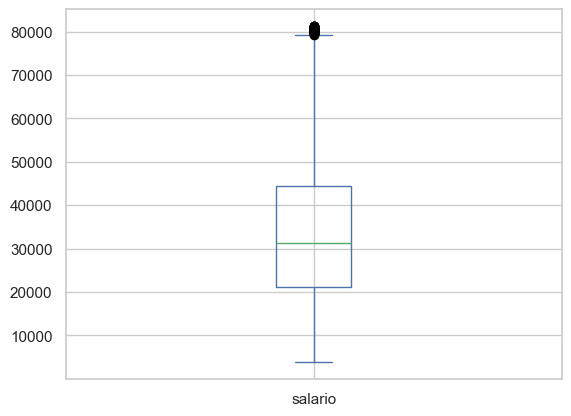

In [80]:
# Grafica de caja para la variable "salario" después de la limpieza
df_trabajo["salario"].plot(kind="box")

In [81]:
# Distribución de variables numéricas


In [82]:
# Identificar las columnas numéricas de df_trabajo
variables_numericas = df_trabajo.select_dtypes(
    include="number"
).columns.tolist()

print("Variables numéricas:", variables_numericas)
print("Total de variables:", len(variables_numericas))

Variables numéricas: ['año', 'salario', 'puntuacion_riesgo_ia', 'puntuacion_demanda_habilidad', 'vacantes_laborales', 'clase_supervivencia_puesto', 'puntuacion_riesgo_ia_original', 'puntuacion_riesgo_ia_clean', 'z_score_vacantes']
Total de variables: 9


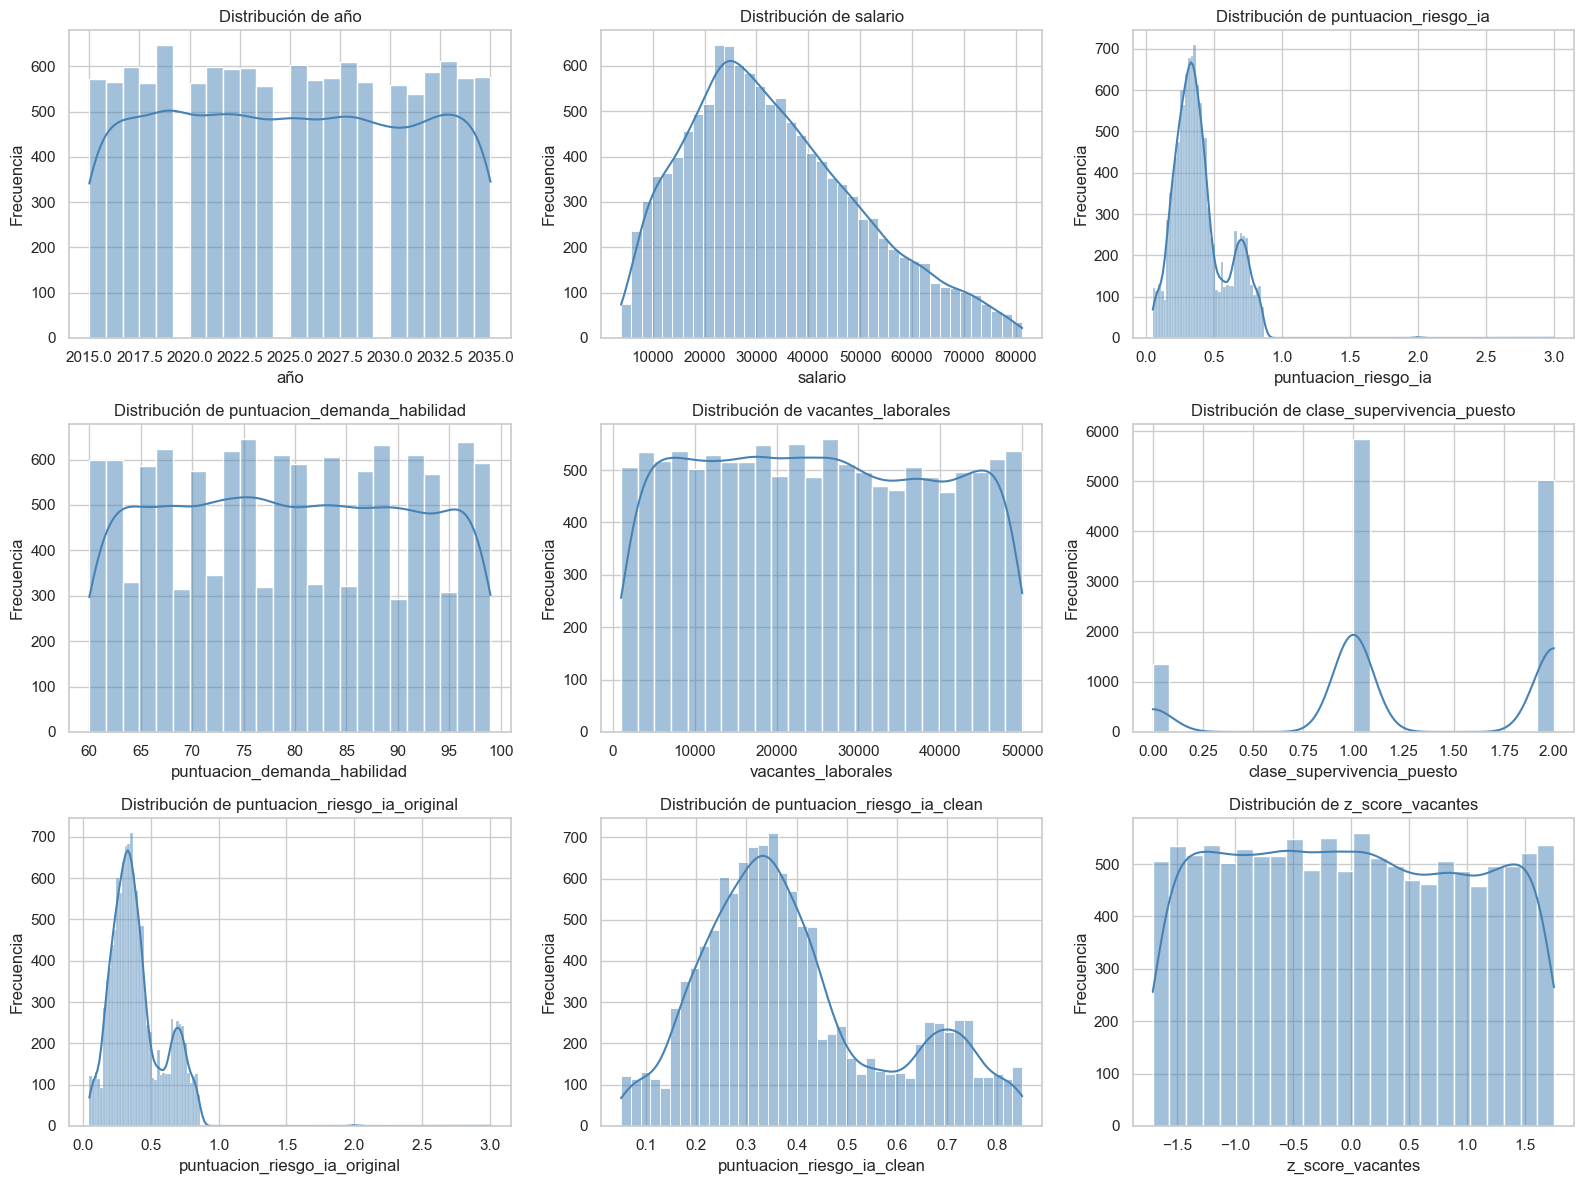

In [83]:
# Configurar el estilo de los gráficos
sns.set_theme(style="whitegrid")

# Definir la cuadrícula de gráficos
n_columnas = 3
n_variables = len(variables_numericas)
n_filas = int(np.ceil(n_variables / n_columnas))

fig, axes = plt.subplots(
    n_filas,
    n_columnas,
    figsize=(16, 4 * n_filas)
)

# Asegurar que axes siempre sea un arreglo unidimensional
axes = np.asarray(axes).reshape(-1)

# Graficar cada variable numérica
for i, variable in enumerate(variables_numericas):

    datos = df_trabajo[variable].dropna()

    sns.histplot(
        data=datos,
        bins="auto",
        kde=(len(datos) > 1 and datos.nunique() > 1),
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(f"Distribución de {variable}")
    axes[i].set_xlabel(variable)
    axes[i].set_ylabel("Frecuencia")

# Ocultar los espacios sobrantes
for j in range(n_variables, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [84]:
# Calcular estadísticas descriptivas
resumen_numerico = df_trabajo[variables_numericas].describe().T

# Añadir medidas de forma de la distribución
resumen_numerico["asimetria"] = (
    df_trabajo[variables_numericas].skew()
)

resumen_numerico["curtosis"] = (
    df_trabajo[variables_numericas].kurtosis()
)

display(resumen_numerico.round(3))

,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis
año,12230.0,2024.970,6.047,2015.00,2020.000,2025.000,2030.000,2035.00,0.015,-1.205
salario,12230.0,33710.275,16755.491,3875.17,21180.460,31237.580,44419.350,81279.59,0.560,-0.298
puntuacion_riesgo_ia,12230.0,0.398,0.193,0.05,0.260,0.360,0.490,3.00,1.025,4.073
puntuacion_demanda_habilidad,12230.0,79.452,11.487,60.00,70.000,79.000,89.000,99.00,0.012,-1.192
vacantes_laborales,12230.0,25256.200,14170.850,1002.00,13007.750,24929.000,37486.750,49998.00,0.041,-1.193
clase_supervivencia_puesto,12230.0,1.300,0.658,0.00,1.000,1.000,2.000,2.00,-0.409,-0.754
puntuacion_riesgo_ia_original,12230.0,0.398,0.193,0.05,0.260,0.360,0.490,3.00,1.025,4.073
puntuacion_riesgo_ia_clean,12230.0,0.397,0.188,0.05,0.260,0.360,0.490,0.85,0.643,-0.376
z_score_vacantes,12230.0,0.003,1.001,-1.71,-0.862,-0.021,0.866,1.75,0.041,-1.193


In [85]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12425 entries, 0 to 12424
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   titulo_puesto                  12425 non-null  object 
 1   pais                           12425 non-null  object 
 2   nivel_experiencia              12425 non-null  object 
 3   nivel_educacion                12425 non-null  object 
 4   año                            12425 non-null  float64
 5   salario                        12425 non-null  float64
 6   puntuacion_riesgo_ia           12425 non-null  float64
 7   habilidad_principal            12425 non-null  object 
 8   puntuacion_demanda_habilidad   12425 non-null  float64
 9   vacantes_laborales             12425 non-null  float64
 10  clase_supervivencia_puesto     12425 non-null  float64
 11  categoria_salario              12425 non-null  object 
 12  categoria_riesgo_ia            12425 non-null 

=== MATRIZ DE CORRELACIÓN DE PEARSON ===
                    vacantes_laborales  z_score_vacantes
vacantes_laborales                 1.0               1.0
z_score_vacantes                   1.0               1.0

=== MATRIZ DE CORRELACIÓN DE SPEARMAN ===
                    vacantes_laborales  z_score_vacantes
vacantes_laborales                 1.0               1.0
z_score_vacantes                   1.0               1.0


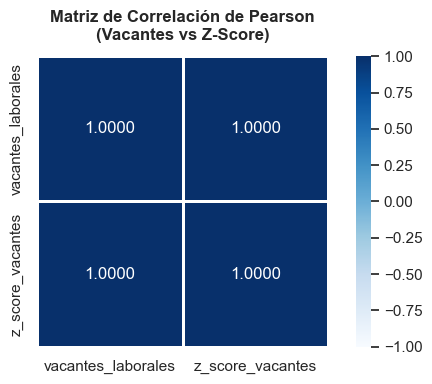

In [86]:
# 1. Asegurar el cálculo de z_score_vacantes en df1
media = df1["vacantes_laborales"].mean()
desviacion = df1["vacantes_laborales"].std()
df1["z_score_vacantes"] = (df1["vacantes_laborales"] - media) / desviacion

# 2. Selección de las variables de interés
variables = ["vacantes_laborales", "z_score_vacantes"]

# 3. Cálculo de matrices de correlación (Pearson y Spearman)
corr_pearson = df1[variables].corr(method="pearson")
corr_spearman = df1[variables].corr(method="spearman")

print("=== MATRIZ DE CORRELACIÓN DE PEARSON ===")
print(corr_pearson.round(4))

print("\n=== MATRIZ DE CORRELACIÓN DE SPEARMAN ===")
print(corr_spearman.round(4))

# 4. Visualización mediante Mapa de Calor (Heatmap)
plt.figure(figsize=(6, 4))
sns.set_theme(style="white")

sns.heatmap(
    corr_pearson,
    annot=True,  # Mostrar los valores numéricos
    fmt=".4f",  # Formato a 4 decimales
    cmap="Blues",  # Paleta de colores azul
    vmin=-1,
    vmax=1,
    cbar=True,
    square=True,
    linewidths=1,
)

plt.title(
    "Matriz de Correlación de Pearson\n(Vacantes vs Z-Score)",
    fontsize=12,
    pad=12,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

In [87]:
# 2. Asegurar el cálculo de la variable estandarizada
media = df1["vacantes_laborales"].mean()
desviacion = df1["vacantes_laborales"].std()
df1["z_score_vacantes"] = (df1["vacantes_laborales"] - media) / desviacion

# 3. Generar la matriz de correlación de Pearson
matriz_correlacion = df1[["vacantes_laborales", "z_score_vacantes"]].corr(
    method="pearson"
)

# 4. Mostrar el resultado
print("=== MATRIZ DE CORRELACIÓN ===")
print(matriz_correlacion.round(4))

=== MATRIZ DE CORRELACIÓN ===
                    vacantes_laborales  z_score_vacantes
vacantes_laborales                 1.0               1.0
z_score_vacantes                   1.0               1.0


In [88]:
# Codigo para elimar las varibles vacantes_laborales y puntuacion_riesgo_ia_original.
df1 = df1.drop(columns=["vacantes_laborales", "puntuacion_riesgo_ia_original"])
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12425 entries, 0 to 12424
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   titulo_puesto                 12425 non-null  object 
 1   pais                          12425 non-null  object 
 2   nivel_experiencia             12425 non-null  object 
 3   nivel_educacion               12425 non-null  object 
 4   año                           12425 non-null  float64
 5   salario                       12425 non-null  float64
 6   puntuacion_riesgo_ia          12425 non-null  float64
 7   habilidad_principal           12425 non-null  object 
 8   puntuacion_demanda_habilidad  12425 non-null  float64
 9   clase_supervivencia_puesto    12425 non-null  float64
 10  categoria_salario             12425 non-null  object 
 11  categoria_riesgo_ia           12425 non-null  object 
 12  puntuacion_riesgo_ia_clean    12425 non-null  float64
 13  z

## Conversión del código fuente en HTML

In [11]:
from pathlib import Path
import nbformat
from nbconvert import HTMLExporter

archivo = Path("S4 - Exploración_de_datos.ipynb") # ruta del archivo notebook que se desea convertir a HTML

if not archivo.is_file():
    raise FileNotFoundError(
        f"No se encontró el archivo: {archivo.resolve()}"
    )

# Leer el notebook
notebook = nbformat.read(archivo, as_version=4)

# Convertir a HTML
exportador = HTMLExporter()
html, recursos = exportador.from_notebook_node(notebook)

salida = archivo.with_suffix(".html")
salida.write_text(html, encoding="utf-8")

print(f"Archivo HTML creado: {salida.resolve()}")

Archivo HTML creado: /Users/eduardomartinez/Library/CloudStorage/OneDrive-InstitutoTecnologicoydeEstudiosSuperioresdeMonterrey/UDF/2026/AD2026/CF3002B/M4 Programación/S4 - EDA/S4 - Exploración_de_datos.html
